# tU 测量强度 β benchmark

扫描 β=0～2.0，检验 `DP_Lib.File_Process2` 返回的量是否随 β 增大趋近零；实际 β 网格读取所选目录的元数据。
下方结论由保存的原始数据计算；不把有限 β 的小正值直接当成严格零。
只需修改下方 `DATA` 一行，然后从头运行全部单元格，即可切换两轮数据；采样量、热化量、分块和结论自动更新。

## 模型与方法

参考 `SCEEtest_M_tU.jl`：HoneyComb120，site=[3,3]（18 格点），t=1，U₁=U₂=3.8，
Δt=0.1，Θrelax=5，Θquench=0，BatchSize=10，Initial="V"；Eidx 固定为所有奇数格点。
A=[1,2,7,8,13,14]，B=[1,2,7,8]。

Nλ=3，分别采样 λ=0、1/3、2/3，而不是只运行 λ=0。
每个 β 独立初始化；在该 β 内逐段延续 HS 场。采样量、热化量和初始化种子说明见所选目录的 `metadata.txt`。
库内部更新 RNG 使用 `time_ns()`，因此重新模拟不保证逐位相同。

观测量是 $X_\lambda=(\det g_A/\det g_B)^{1/3}$，每个 CSV 数值已是一个 sweep 的时间片平均。
直接调用 `File_Process2(..., throw=0)` 得到
$\Delta S_2=-\log\prod_\lambda\overline{X_\lambda}$ 和原函数的误差。
这对应 A、B 的二阶 Rényi 熵差，不能据此分别断言两区域的熵都为零。
β 是测量强度，不是这里的投影长度或逆温度。

原函数误差把 sweeps 当作独立样本；另用分块均值估计误差作诊断，块长根据所选样本数自动确定。
分块仍假定块之间、λ 段之间近似独立，不是严格收敛证明。


In [1]:
from pathlib import Path
import sys, csv, re, hashlib, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.options.display.float_format = "{:.6g}".format

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'DP_Lib.py').exists())
HERE = ROOT / 'test' / 'tU_Measure'
DATA = HERE / 'benchmark_beta_data_10000'
# Switch only the line above to: DATA = HERE / 'benchmark_beta_data'
sys.path.insert(0, str(ROOT))
from DP_Lib import File_Process2, combine_data
plt.rcParams.update({'figure.dpi': 140, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
metadata = (DATA / 'metadata.txt').read_text(encoding='utf-8')
settings = dict(line.split('=', 1) for line in metadata.splitlines() if '=' in line)
N_SWEEPS = int(settings['sweeps'])
WARMUP = int(settings['warmup'])
N_LAMBDA = int(settings['Nlambda'])
BETAS = np.asarray(ast.literal_eval(settings['betas']), dtype=float)
assert N_SWEEPS >= 20
BLOCK_SIZE = max(b for b in range(1, min(100, N_SWEEPS // 20) + 1) if N_SWEEPS % b == 0)
display(Markdown(f'**当前数据：`{DATA.name}`**；每段采样 **{N_SWEEPS}** sweeps，热化 **{WARMUP}** sweeps，分块长度 **{BLOCK_SIZE}**。'))
print(metadata)
for line in metadata.splitlines():
    if ' sha256=' in line:
        relative, digest = line.split(' sha256=')
        current = hashlib.sha256((ROOT / relative).read_bytes()).hexdigest()
        if current != digest:
            print('WARNING: source changed since simulation:', relative)


**当前数据：`benchmark_beta_data_10000`**；每段采样 **10000** sweeps，热化 **1000** sweeps，分块长度 **100**。

Julia=1.12.1
sweeps=10000
warmup=1000
betas=[0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
Nlambda=3
Theta_relax=5.0
Eidx=[1, 3, 5, 7, 9, 11, 13, 15, 17]
indexA=[1, 2, 7, 8, 13, 14]
indexB=[1, 2, 7, 8]
Initialization seeds=1235+round(5*beta). Library update RNG uses time_ns; reruns are statistical, not bitwise identical.
src/tU/SCEE_M.jl sha256=4976fc3ae79c85f83c41b7ec44456b00216677d26ff3219e65c5ef6b4b6094c1
test/tU_Measure/SCEEtest_M_tU.jl sha256=00fbc59291f73743a2328b039c4eabac15b1ab658ad2d7452f2006a1884e79af
DP_Lib.py sha256=8da8fe05048d1f57891528e7d5b2c091d432de9d47baf30d2576cf3a9363132d



## 数据检查与直接处理
按元数据检查 β、λ 和每段样本数，检查有限正值；保留所有生产样本，不裁剪极值。

In [2]:
def estimate(values):
    means = values.mean(axis=1)
    return -np.log(means).sum(), np.sqrt(np.sum((values.std(axis=1, ddof=1) / np.sqrt(values.shape[1]) / means)**2))

records, raw = [], {}
for file in DATA.glob('*SCEE*.csv'):
    beta = float(re.search(r'M([0-9.]+)\.csv$', file.name).group(1))
    with file.open(encoding='utf-8', newline='') as f:
        rows = list(csv.reader(f))
    assert len(rows) == N_LAMBDA and all(len(row) == N_SWEEPS + 1 for row in rows), file.name
    data = combine_data(rows)
    data = data[np.argsort(data[:, 0])]
    assert np.allclose(data[:, 0], np.arange(N_LAMBDA) / N_LAMBDA)
    values = data[:, 1:]
    assert np.isfinite(values).all() and (values > 0).all()
    ee, dee = File_Process2(file.name, str(file.parent), throw=0, subEEfig=False)
    check, check_err = estimate(values)
    assert np.allclose([ee, dee], [check, check_err], rtol=1e-10, atol=1e-12)
    block_means = values.reshape(N_LAMBDA, N_SWEEPS // BLOCK_SIZE, BLOCK_SIZE).mean(axis=2)
    _, block_error = estimate(block_means)
    first, _ = estimate(values[:, :N_SWEEPS // 2])
    last, _ = estimate(values[:, N_SWEEPS // 2:])
    records.append(dict(beta=beta, EE=ee, dEE=dee, block_SE=block_error,
                        first_half=first, second_half=last, samples_per_lambda=N_SWEEPS))
    raw[beta] = values
result = pd.DataFrame(records).sort_values('beta').reset_index(drop=True)
assert len(result) == len(BETAS) and np.allclose(result.beta, np.sort(BETAS))
result.to_csv(HERE / 'benchmark_beta_summary.csv', index=False)
display(result)


,beta,EE,dEE,block_SE,first_half,second_half,samples_per_lambda
0,0,0.0431003,0.0032337,0.00384461,0.046905,0.0393225,10000
1,0.05,0.0231656,0.0026651,0.00333341,0.0174648,0.0288892,10000
2,0.1,0.0091593,0.00219702,0.00251445,0.0111069,0.00721306,10000
3,0.15,0.00554577,0.0018098,0.00212036,0.00362529,0.00746858,10000
4,0.2,0.00272556,0.00149265,0.0016771,0.00114423,0.00430934,10000
5,0.25,0.00191705,0.00124163,0.00141634,0.00206315,0.00177465,10000
6,0.3,-7.69148e-05,0.00102772,0.00124164,-0.000254765,0.000101064,10000
7,0.4,-0.00108278,0.000709318,0.00082901,-0.000799309,-0.00136581,10000
8,0.6,-0.000469085,0.000334492,0.000378213,-0.000741581,-0.000196461,10000
9,0.8,-3.91345e-05,0.000161507,0.000178315,-7.70597e-05,-1.18838e-06,10000


## 两轮数据对照（固定对照表）
此表始终分别读取两轮目录，不受主分析 `DATA` 选择影响。两轮分别调用 `File_Process2`，不合并样本；误差不包含自相关修正。仅在一轮采样的 β 点仍保留，另一轮显示 NaN（未采样），不填成零。

In [3]:
tables = []
for folder_name, sample_count in [('benchmark_beta_data', 1000), ('benchmark_beta_data_10000', 10000)]:
    rows = []
    for file in (HERE / folder_name).glob('*SCEE*.csv'):
        beta = float(re.search(r'M([0-9.]+)\.csv$', file.name).group(1))
        ee, dee = File_Process2(file.name, str(file.parent), throw=0, subEEfig=False)
        rows.append({'beta': beta, f'EE_{sample_count}': ee, f'SE_{sample_count}': dee})
    tables.append(pd.DataFrame(rows))
if all(not table.empty for table in tables):
    comparison = tables[0].merge(tables[1], on='beta', how='outer', validate='one_to_one').sort_values('beta')
    comparison['SE_reduction_factor'] = comparison.SE_1000 / comparison.SE_10000
    display(comparison)
else:
    print('Comparison skipped: one of the two reference datasets is unavailable.')


,beta,EE_1000,SE_1000,EE_10000,SE_10000,SE_reduction_factor
0,0,0.0301604,0.0102138,0.0431003,0.0032337,3.15856
1,0.05,NaN,NaN,0.0231656,0.0026651,NaN
2,0.1,NaN,NaN,0.0091593,0.00219702,NaN
3,0.15,NaN,NaN,0.00554577,0.0018098,NaN
4,0.2,0.00927617,0.00460782,0.00272556,0.00149265,3.087
5,0.25,NaN,NaN,0.00191705,0.00124163,NaN
6,0.3,NaN,NaN,-7.69148e-05,0.00102772,NaN
7,0.4,0.00317143,0.00224353,-0.00108278,0.000709318,3.16294
8,0.6,8.42547e-05,0.00107118,-0.000469085,0.000334492,3.2024
9,0.8,-0.00121875,0.000518444,-3.91345e-05,0.000161507,3.21003


## β 趋势与零值检验
主图误差条为 `File_Process2` 的 ±1 标准误；放大图同时展示分块的 ±1 标准误，块长见图例。连线仅辅助观察。

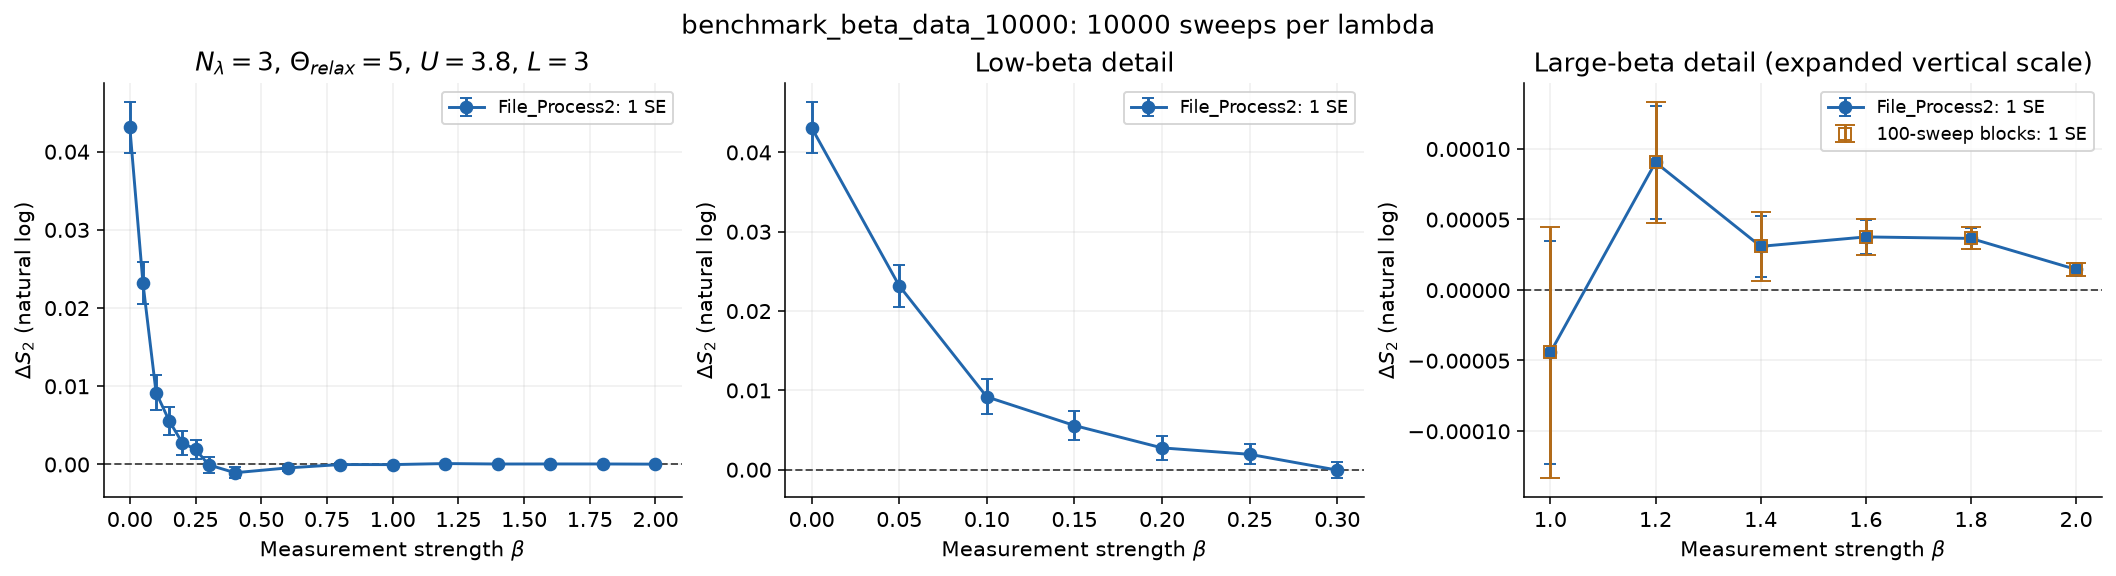

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
fig.suptitle(f'{DATA.name}: {N_SWEEPS} sweeps per lambda')
for ax, subset in zip(axes, [result, result[result.beta <= 0.3], result[result.beta >= 1.0]]):
    ax.errorbar(subset.beta, subset.EE, yerr=subset.dEE, fmt='o-', color='#2166ac',
                capsize=3, label='File_Process2: 1 SE')
    ax.axhline(0, color='.3', lw=1, ls='--')
    ax.set_xlabel(r'Measurement strength $\beta$')
    ax.set_ylabel(r'$\Delta S_2$ (natural log)')
axes[0].set_title(r'$N_\lambda=3$, $\Theta_{relax}=5$, $U=3.8$, $L=3$')
axes[1].set_title('Low-beta detail')
axes[1].set_xticks(np.arange(0, 0.301, 0.05))
tail = result[result.beta >= 1.0]
axes[2].errorbar(tail.beta, tail.EE, yerr=tail.block_SE, fmt='s', mfc='none',
                 color='#b56b16', capsize=5, label=f'{BLOCK_SIZE}-sweep blocks: 1 SE')
axes[2].set_title('Large-beta detail (expanded vertical scale)')
for ax in axes:
    ax.legend(fontsize=9)
plt.show()


## 采样稳定性诊断
累计估计、分块长度敏感性及前后半段差异用于提示热化或自相关问题；单链结果不能排除慢模。

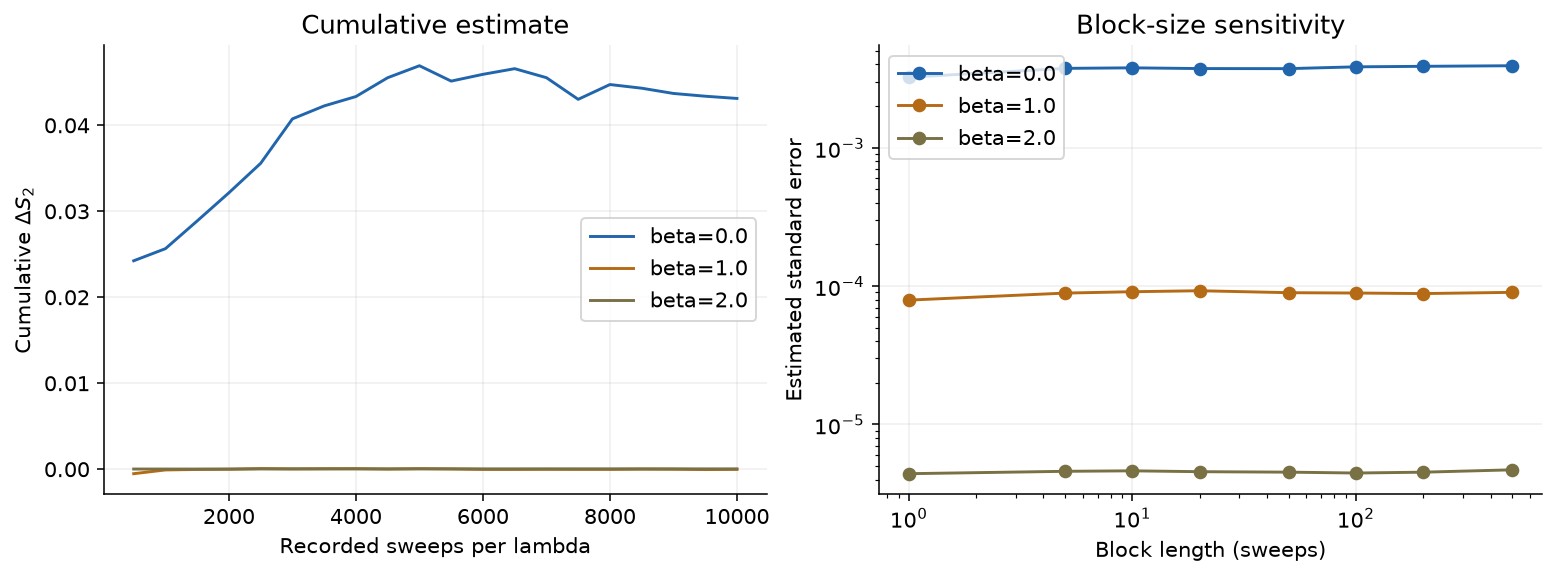

,beta,first_half,second_half,block_SE
0,0,0.046905,0.0393225,0.00384461
1,0.05,0.0174648,0.0288892,0.00333341
2,0.1,0.0111069,0.00721306,0.00251445
3,0.15,0.00362529,0.00746858,0.00212036
4,0.2,0.00114423,0.00430934,0.0016771
5,0.25,0.00206315,0.00177465,0.00141634
6,0.3,-0.000254765,0.000101064,0.00124164
7,0.4,-0.000799309,-0.00136581,0.00082901
8,0.6,-0.000741581,-0.000196461,0.000378213
9,0.8,-7.70597e-05,-1.18838e-06,0.000178315


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
selected = [0.0, 1.0, 2.0]
colors = ['#2166ac', '#b56b16', '#797044']
for beta, color in zip(selected, colors):
    values = raw[beta]
    stops = np.unique(np.linspace(max(2, N_SWEEPS // 20), N_SWEEPS, 20, dtype=int))
    axes[0].plot(stops, [estimate(values[:, :n])[0] for n in stops], label=f'beta={beta}', color=color)
    lengths = [b for b in [1, 5, 10, 20, 50, 100, 200, 500] if N_SWEEPS % b == 0 and N_SWEEPS // b >= 10]
    errors = [estimate(values.reshape(N_LAMBDA, N_SWEEPS//b, b).mean(axis=2))[1] for b in lengths]
    axes[1].plot(lengths, errors, 'o-', label=f'beta={beta}', color=color)
axes[0].set(xlabel='Recorded sweeps per lambda', ylabel=r'Cumulative $\Delta S_2$', title='Cumulative estimate')
axes[1].set(xlabel='Block length (sweeps)', ylabel='Estimated standard error', title='Block-size sensitivity', xscale='log', yscale='log')
for ax in axes:
    ax.legend()
plt.show()
display(result[['beta', 'first_half', 'second_half', 'block_SE']])


## 结果解读

In [6]:
start, end = result.iloc[0], result.iloc[-1]
monotone = bool((np.diff(result.EE) <= 0).all())
z = abs(end.EE) / end.block_SE
display(Markdown(
    f'**当前分析：`{DATA.name}`，{N_SWEEPS} sweeps/λ。**\n\n'
    f'- β=0：**{start.EE:.6g} ± {start.dEE:.6g}**（File_Process2 标准误）。\n'
    f'- β=2：**{end.EE:.6g} ± {end.dEE:.6g}**；分块标准误 **{end.block_SE:.6g}**。\n'
    f'- 相比 β=0，末点绝对值比例为 **{abs(end.EE/start.EE):.3%}**。\n'
    f'- 网格上的点估计严格非增：**{monotone}**。\n'
    f'- β=2 距零约 **{z:.2f} 个分块标准误**；'
    + ('与零在约 2 SE 范围内相容，但这不是证明严格为零。' if z <= 2 else '仍不与零在约 2 SE 范围内相容，不能说 β=2 已经为零。')
    + '\n\n以上结论仅描述当前参数和有限扫描区间；不外推证明 β→∞ 极限，也不把熵差当成单一区域熵。'
))


**当前分析：`benchmark_beta_data_10000`，10000 sweeps/λ。**

- β=0：**0.0431003 ± 0.0032337**（File_Process2 标准误）。
- β=2：**1.4526e-05 ± 4.40901e-06**；分块标准误 **4.45824e-06**。
- 相比 β=0，末点绝对值比例为 **0.034%**。
- 网格上的点估计严格非增：**False**。
- β=2 距零约 **3.26 个分块标准误**；仍不与零在约 2 SE 范围内相容，不能说 β=2 已经为零。

以上结论仅描述当前参数和有限扫描区间；不外推证明 β→∞ 极限，也不把熵差当成单一区域熵。

## 复现

在仓库根目录运行：
```powershell
julia --project=. test/tU_Measure/benchmark_beta.jl test/tU_Measure/benchmark_beta_data_new
```
脚本拒绝写入已有目录，避免库的追加模式混合新旧运行。要分析新运行，将本 notebook 的 `DATA` 改为新目录。
Julia 脚本默认网格为 0:0.2:2；复现加密网格时，将环境变量 `BENCH_BETAS` 设为所选元数据中的 β 列表（逗号分隔、不带方括号）。
Python 依赖：numpy、pandas、scipy、matplotlib、nbformat、nbclient、ipykernel。
重新运行 notebook 只处理保存的 CSV，不自动重跑模拟；图形仅内嵌于 notebook，不导出图片文件。
两轮目录均为根目录下的 CSV 和 `metadata.txt`；运行信息只输出到终端，不生成日志文件。
追加新 β 点可运行 `python test/tU_Measure/run_beta_extended.py --append --betas ...`，已有 β 会被拒绝以避免混合重复采样。
切换数据时只需修改 `DATA`，然后重启内核并运行全部单元格。顶部不保存固定数值摘要，结果解读由当前数据动态生成。
